In [ ]:
from google.colab import drive
import os, sys, json

drive.mount('/content/drive')
BASE_DIR = "/content/drive/MyDrive/simuteh-2330511031"
os.chdir(os.path.join(BASE_DIR, "notebook"))
sys.path.append("../src")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)

# Verifikasi otomatis Lembar Hitung 3.1
B = np.array([
    [0,0,0,0,0,0,0,0,0],
    [0,1,1,1,0,0,0,0,0],
    [0,1,0,1,0,0,0,1,0],
    [0,1,1,1,0,0,0,0,0],
    [0,0,0,0,1,0,0,0,0],
    [0,0,0,0,0,0,0,0,0],
    [0,0,0,0,0,0,0,0,0],
    [0,1,1,1,1,1,1,0,0],
    [0,0,0,0,0,0,0,0,0]
], dtype=np.uint8)
se3 = np.ones((3, 3), np.uint8)
print("3.1(a) Komponen konek-4:", cv2.connectedComponents(B, connectivity=4)[0] - 1,
      "| konek-8:", cv2.connectedComponents(B, connectivity=8)[0] - 1)
print("3.1(b) Piksel sisa Erosi:", cv2.erode(B, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0).sum(),
      "| Opening:", cv2.morphologyEx(B, cv2.MORPH_OPEN, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0).sum())
close_B = cv2.morphologyEx(B, cv2.MORPH_CLOSE, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
open_close_B = cv2.morphologyEx(close_B, cv2.MORPH_OPEN, se3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
print("3.1(c) Hasil Closing B:\n", close_B)
print("3.1(d) Hasil Opening(Closing(B)):\n", open_close_B)

Mounted at /content/drive
3.1(a) Komponen konek-4: 4 | konek-8: 3
3.1(b) Piksel sisa Erosi: 0 | Opening: 0
3.1(c) Hasil Closing B:
 [[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]
3.1(d) Hasil Opening(Closing(B)):
 [[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.993                    80              11           0.623
1  teh_021.png          0.999                   119               3           0.124
2  teh_011.png          0.999                   201               0               -


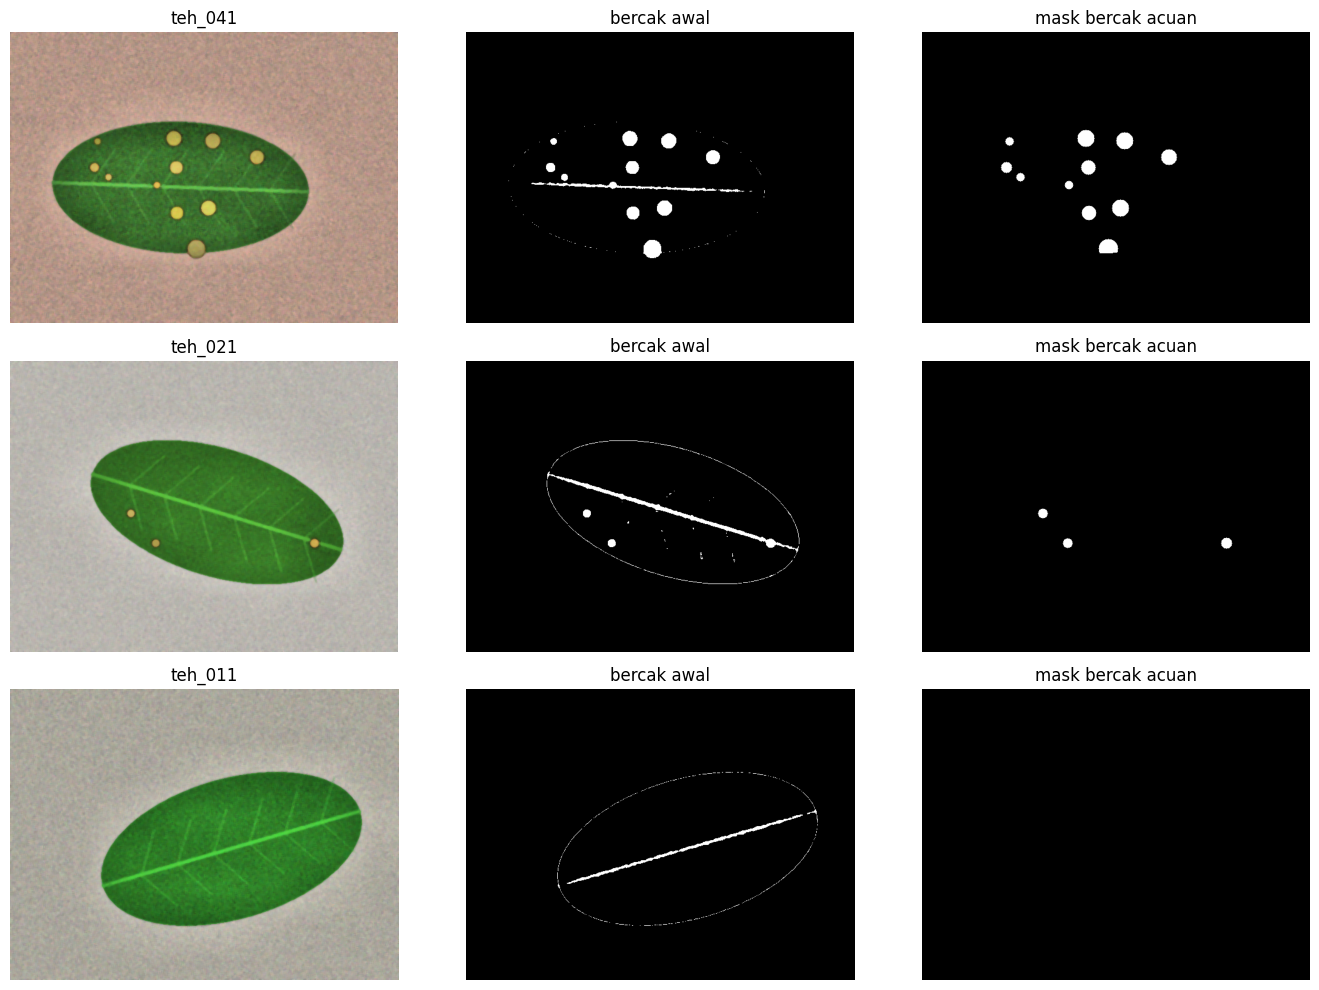

In [ ]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:   # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]

print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal",
                                   "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))

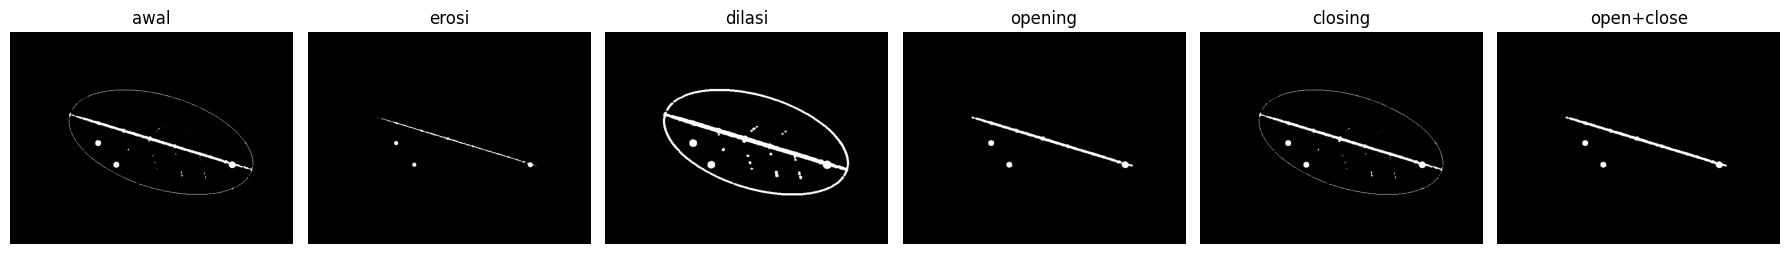

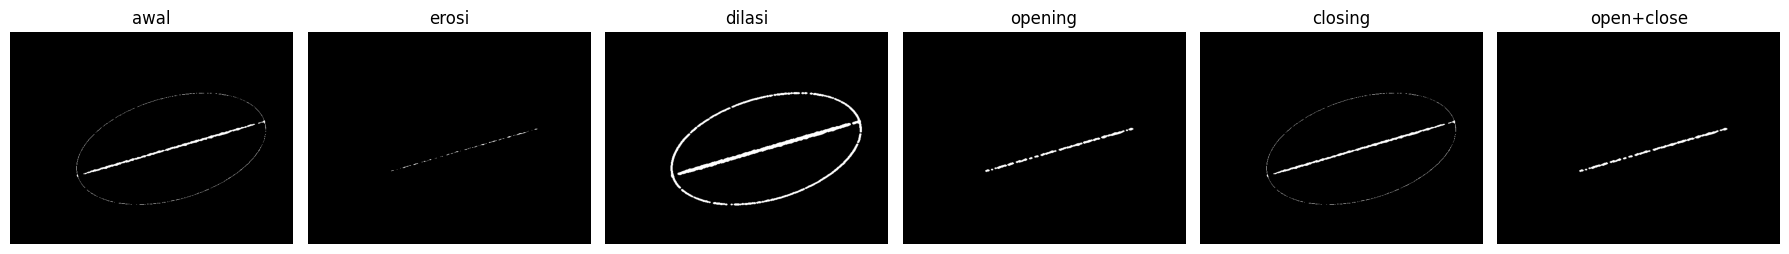

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       119    3756  0.124
1   teh_021.png       erosi         8    1030  0.173
2   teh_021.png      dilasi        16   10175  0.064
3   teh_021.png     opening         4    2652   0.17
4   teh_021.png     closing       111    3802  0.122
5   teh_021.png  open+close         3    2668  0.169
6   teh_011.png        awal       201    2450      -
7   teh_011.png       erosi        45     254      -
8   teh_011.png      dilasi        12    8191      -
9   teh_011.png     opening        13    1386      -
10  teh_011.png     closing       197    2493      -
11  teh_011.png  open+close        11    1408      -


In [ ]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()),
                      round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3)); plt.show()

print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

In [ ]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan),
                              iou(m, mb) if mb.any() else np.nan])

eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
piv_eks = eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2)
print("=== PIVOT LENGKAP EKSPERIMEN k, BENTUK, UKURAN SE ===")
print(piv_eks)
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)

# Cetak khusus Format Tabel 9 (untuk k = 4)
eks_k4 = eks[eks.k == 4]
iou_k4 = eks_k4.pivot_table(index=["bentuk", "ukuran"], columns="kelas", values="IoU").round(2)
gal_k4 = eks_k4.pivot_table(index=["bentuk", "ukuran"], columns="kelas", values="galat_jumlah").round(2)
tabel_9 = pd.DataFrame({
    "IoU berat": iou_k4["berat"],
    "IoU ringan": iou_k4["ringan"],
    "Galat jumlah berat": gal_k4["berat"],
    "Galat jumlah ringan": gal_k4["ringan"],
    "Galat jumlah sehat": gal_k4["sehat"],
}).loc[[(b, u) for b in ["persegi", "elips", "silang"] for u in [3, 5, 7]]]
print("\n=== FORMAT TABEL 9 (KHUSUS k = 4) ===")
print(tabel_9)

=== PIVOT LENGKAP EKSPERIMEN k, BENTUK, UKURAN SE ===
                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.62   0.12        11.85   9.20  10.65
          5       0.65   0.16         2.90   4.35   4.45
          7       0.73   0.34         2.10   2.75   4.25
  persegi 3       0.62   0.13         5.00   5.80   7.55
          5       0.68   0.22         2.20   3.90   4.15
          7       0.76   0.41         0.25   1.25   0.45
  silang  3       0.62   0.12        11.85   9.20  10.65
          5       0.65   0.17         4.65   6.85   7.20
          7       0.73   0.32         3.35   3.95   6.65
4 elips   3       0.66   0.22        11.30   8.40   7.60
          5       0.70   0.32         3.20   3.10   4.90
          7       0.75   0.45         0.40   1.70   1.20
  persegi 3       0.67   0.24         5.40   6.35   6.05
          5       0.73   0.38     

In [ ]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))   # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])

print("=== PERBANDINGAN F1 GRADIEN MORFOLOGI VS CANNY (BATAS DAUN) ===")
print(pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"])
        .groupby("kondisi").mean().round(3))

=== PERBANDINGAN F1 GRADIEN MORFOLOGI VS CANNY (BATAS DAUN) ===
                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.981     0.715
gelap                          0.993     0.715
kontras_rendah                 0.693     0.895
normal                         0.992     0.697
terang                         0.982     0.757


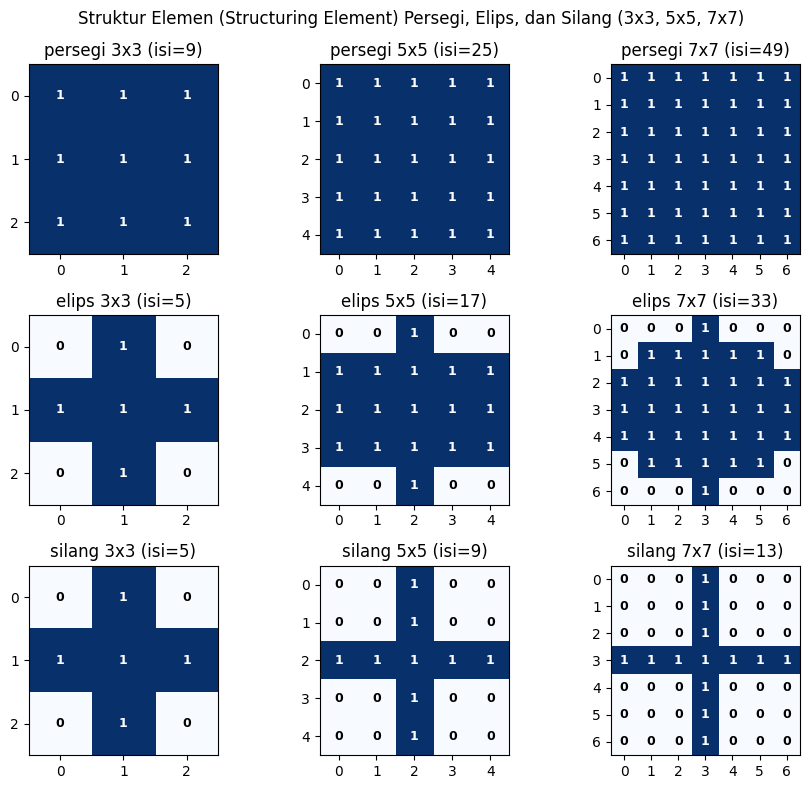

In [ ]:
# Langkah 3.6: Tampilkan elemen SE persegi, elips, dan silang berukuran 3, 5, dan 7 dalam satu panel
fig, axes = plt.subplots(3, 3, figsize=(9, 8))
urutan_bentuk = [("persegi", cv2.MORPH_RECT), ("elips", cv2.MORPH_ELLIPSE), ("silang", cv2.MORPH_CROSS)]
urutan_ukuran = [3, 5, 7]

for i, (nama_b, kode_b) in enumerate(urutan_bentuk):
    for j, uk in enumerate(urutan_ukuran):
        elemen = cv2.getStructuringElement(kode_b, (uk, uk))
        ax = axes[i, j]
        ax.imshow(elemen, cmap="Blues", vmin=0, vmax=1)
        ax.set_title(f"{nama_b} {uk}x{uk} (isi={int(elemen.sum())})")
        ax.set_xticks(range(uk)); ax.set_yticks(range(uk))
        for r in range(uk):
            for c in range(uk):
                ax.text(c, r, str(elemen[r, c]), ha="center", va="center",
                        color="white" if elemen[r, c] else "black", fontsize=9, fontweight="bold")

plt.suptitle("Struktur Elemen (Structuring Element) Persegi, Elips, dan Silang (3x3, 5x5, 7x7)", fontsize=12)
plt.tight_layout()
plt.savefig("../hasil/p6_panel_se.png", dpi=150)
plt.show()

konektivitas 4: 21 komponen
konektivitas 8: 21 komponen

=== TABEL 10: UKURAN SETIAP KOMPONEN PADA teh_041 ===
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      495     94.75         80.2       0.97         1.00  269  175
1       2      495     94.75         80.2       0.97         1.00  334  179
2       3       94     17.99         33.6       1.05         1.00  144  179
3       4      428     81.92         74.5       0.97         1.00  406  206
4       5      376     71.97         69.5       0.98         1.00  273  222
5       6      189     36.18         48.4       1.01         1.00  139  222
6       7      106     20.29         36.1       1.02         1.10  162  239
7       8      126     24.12         41.2       0.93         1.16  242  252
8       9       35      6.70         21.1       0.99         1.40  161  251
9      10      217     41.54        122.6       0.18        10.11  198  252
10     11       22      4.21         15.7       1.13 

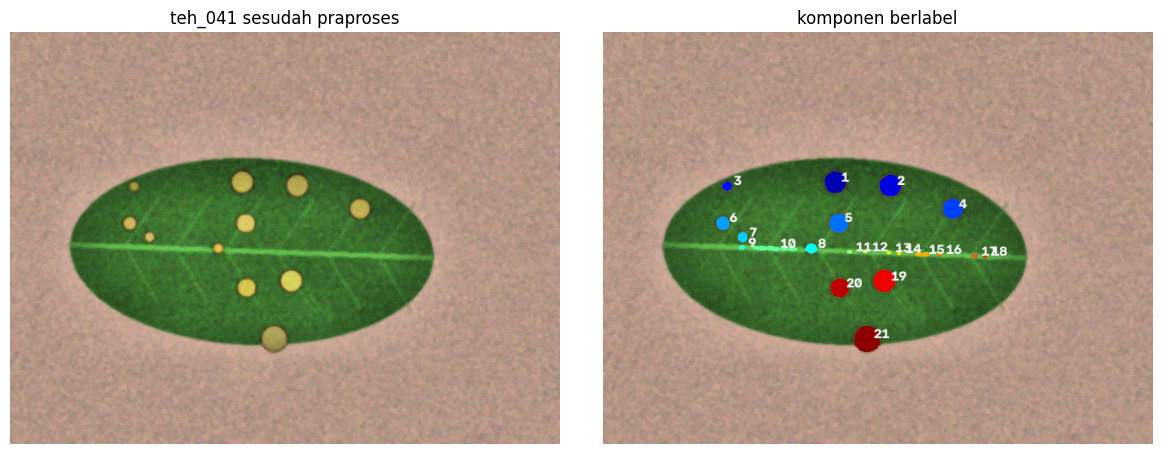

In [ ]:
MM_PER_PX = 0.4375   # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL,
                                     cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                          cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print("\n=== TABEL 10: UKURAN SETIAP KOMPONEN PADA teh_041 ===")
print(tabel_kom)
tabel_kom.to_csv("../hasil/p6_tabel10_teh041.csv", index=False)

warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))

In [ ]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min)
                    & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])

uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()

piv_galat = uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2)
daun_palsu = uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum()

tabel_11 = pd.DataFrame({
    "Galat jumlah berat": piv_galat["berat"],
    "Galat jumlah ringan": piv_galat["ringan"],
    "Galat jumlah sehat": piv_galat["sehat"],
    "Daun sehat dengan bercak palsu": daun_palsu
}).loc[["tanpa saring", "luas >= 20", "luas + kebulatan", "luas + kebulatan + rasio"]]

print("=== FORMAT TABEL 11 ===")
print(tabel_11)
tabel_11.to_csv("../hasil/p6_tabel11_saring.csv")

# Tambahan hitung luas bercak teh_041 vs mask acuan untuk menjawab P4.4
img41, md41, mb41 = muat("teh_041.png")
pra41 = praproses(img41, PARAM)
md_awal41 = mask_daun_awal(pra41)
bersih41 = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra41, md_awal41), cv2.MORPH_OPEN, SE(5)),
                            cv2.MORPH_CLOSE, SE(5))
f41, lolos41 = saring(bersih41, 20, 0.5, 1.8)
luas_acuan_px = int((mb41 > 0).sum())
luas_sebelum_saring_px = int((bersih41 > 0).sum())
luas_sesudah_saring_px = int((f41 > 0).sum())
print("\n=== PERBANDINGAN LUAS BERCAK teh_041 (UNTUK P4.4) ===")
print(f"Luas acuan (mb)         : {luas_acuan_px} px ({round(luas_acuan_px * MM_PER_PX**2, 2)} mm2)")
print(f"Luas bersih (tanpa saring): {luas_sebelum_saring_px} px | selisih: {round((luas_sebelum_saring_px - luas_acuan_px)/luas_acuan_px*100, 2)}%")
print(f"Luas hasil tersaring    : {luas_sesudah_saring_px} px ({round(luas_sesudah_saring_px * MM_PER_PX**2, 2)} mm2) | selisih: {round((luas_sesudah_saring_px - luas_acuan_px)/luas_acuan_px*100, 2)}%")

=== FORMAT TABEL 11 ===
                          Galat jumlah berat  Galat jumlah ringan  Galat jumlah sehat  Daun sehat dengan bercak palsu
aturan                                                                                                               
tanpa saring                            3.20                 3.10                4.90                              15
luas >= 20                              2.45                 2.20                3.95                              14
luas + kebulatan                        2.05                 1.55                2.35                              13
luas + kebulatan + rasio                1.25                 0.90                1.20                              11

=== PERBANDINGAN LUAS BERCAK teh_041 (UNTUK P4.4) ===
Luas acuan (mb)         : 4571 px (874.92 mm2)
Luas bersih (tanpa saring): 4367 px | selisih: -4.46%
Luas hasil tersaring    : 4010 px (767.54 mm2) | selisih: -12.27%


=== RINGKASAN KOMPONEN BENAR VS PALSU PADA 60 CITRA ===
       luas_px                  kebulatan                    rasio_aspek                   
         count min median   max     count   min median   max       count  min median    max
status                                                                                     
Benar      211  22  226.0  3656       211  0.06   0.98  1.13         211  1.0   1.04   9.32
Palsu      229   1   36.0  2392       229  0.00   0.90  1.18         229  0.0   1.89  51.09


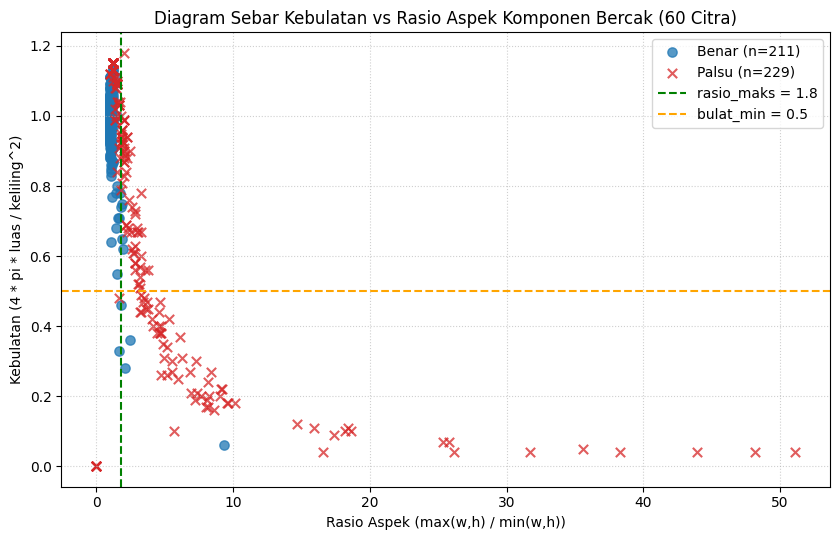

In [ ]:
# Langkah 4.4: Tandai komponen "benar" (> 50% piksel di mask_bercak acuan) vs "palsu" pada 60 citra
komponen_60 = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)),
                              cv2.MORPH_CLOSE, SE(5))
    tk, lbl_k = ukur_komponen(bersih)
    acuan_bin = (mb > 0)
    for _, r in tk.iterrows():
        mask_i = (lbl_k == int(r.label))
        porsi_irisan = float((mask_i & acuan_bin).sum()) / float(mask_i.sum())
        status = "Benar" if porsi_irisan > 0.5 else "Palsu"
        komponen_60.append([d.nama_file, d.kelas, int(r.luas_px), float(r.kebulatan),
                            float(r.rasio_aspek), porsi_irisan, status])

df_kom60 = pd.DataFrame(komponen_60, columns=["nama", "kelas", "luas_px", "kebulatan", "rasio_aspek", "porsi_acuan", "status"])
print("=== RINGKASAN KOMPONEN BENAR VS PALSU PADA 60 CITRA ===")
print(df_kom60.groupby("status")[["luas_px", "kebulatan", "rasio_aspek"]].agg(["count", "min", "median", "max"]).round(2))

# Buat diagram sebar kebulatan terhadap rasio aspek
plt.figure(figsize=(8.5, 5.5))
for st, warna_st, marker_st in [("Benar", "#1f77b4", "o"), ("Palsu", "#d62728", "x")]:
    sub = df_kom60[df_kom60.status == st]
    plt.scatter(sub.rasio_aspek, sub.kebulatan, c=warna_st, marker=marker_st,
                alpha=0.75, s=45, label=f"{st} (n={len(sub)})")

plt.axvline(1.8, color="green", linestyle="--", linewidth=1.5, label="rasio_maks = 1.8")
plt.axhline(0.5, color="orange", linestyle="--", linewidth=1.5, label="bulat_min = 0.5")
plt.xlabel("Rasio Aspek (max(w,h) / min(w,h))")
plt.ylabel("Kebulatan (4 * pi * luas / keliling^2)")
plt.title("Diagram Sebar Kebulatan vs Rasio Aspek Komponen Bercak (60 Citra)")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../hasil/p6_scatter_komponen.png", dpi=150)
plt.show()

In [ ]:
kode_bercak = '''"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,             # kanal terpilih (2 = R)
    "k": 4.0,               # ambang median + k x MAD
    "se_bentuk": "elips",   # "elips", "persegi", "silang"
    "se_open": 5,           # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,          # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,         # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,    # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,     # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}
_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1: bila p["se_open"] > 0, lakukan opening dengan SE _se(p, p["se_open"])
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    # TODO 2: bila p["se_close"] > 0, lakukan closing dengan SE _se(p, p["se_close"])
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    keluar, daftar = np.zeros_like(biner), []
    # TODO 3: label komponen terhubung (konektivitas 8) dengan cv2.connectedComponentsWithStats
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    # TODO 4: untuk setiap komponen hitung luas, keliling (cv2.arcLength),
    #         kebulatan 4*pi*luas/keliling^2, dan rasio aspek (cv2.minAreaRect)
    for i in range(1, n):
        komp = (lbl == i).astype(np.uint8)
        kontur, _ = cv2.findContours(komp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not kontur:
            continue
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = float(cv2.arcLength(kontur[0], True))
        kebulatan = 0.0 if keliling == 0 else float(4 * np.pi * A / (keliling ** 2))
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = float(max(w, h) / max(min(w, h), 1))
        # TODO 5: simpan ke mask keluar hanya komponen yang memenuhi luas_min,
        #         bulat_min, dan rasio_maks; catat ukurannya ke daftar
        if A >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({
                "label": len(daftar) + 1,
                "luas_px": A,
                "luas_mm2": round(A * (p["mm_per_px"] ** 2), 2),
                "keliling_px": round(keliling, 1),
                "kebulatan": round(kebulatan, 2),
                "rasio_aspek": round(rasio, 2),
                "cx": int(cen[i][0]),
                "cy": int(cen[i][1]),
            })
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    # TODO 6: hitung persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    luas_bercak = int((m_bercak > 0).sum())
    persen = 0.0 if luas_daun == 0 else (luas_bercak / luas_daun) * 100.0
    # TODO 7: tentukan kelas dengan batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
            "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)
'''

with open("../src/bercak.py", "w") as f:
    f.write(kode_bercak)
print("src/bercak.py berhasil disimpan!")

src/bercak.py berhasil disimpan!


Galat absolut rerata persen bercak: 0.575
Korelasi persen prediksi vs acuan : 0.957
Akurasi kelas                     : 0.867
Sehat dinilai berbercak           : 4
Berbercak dinilai sehat           : 4

=== MATRIKS KEKELIRUAN ===
prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             20              0      0
Bercak Ringan             0             16      4
Sehat                     0              4     16

=== AKURASI PER KONDISI CAHAYA ===
kondisi
bayangan          0.83
gelap             0.83
kontras_rendah    0.92
normal            0.92
terang            0.83
Name: benar, dtype: float64


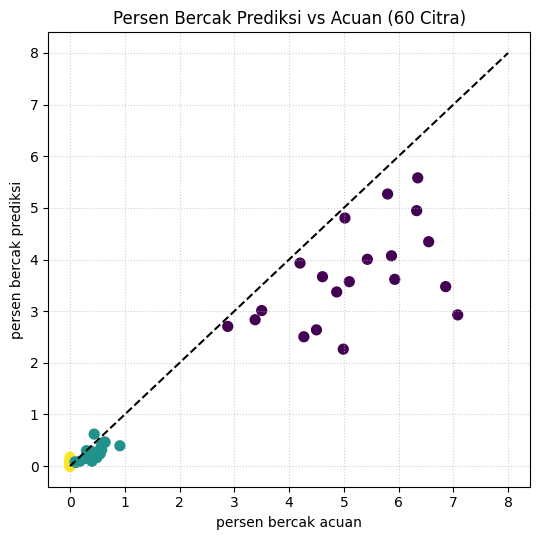

In [ ]:
import importlib, bercak
importlib.reload(bercak)
PB = {}                                      # memakai nilai bawaan sesuai temuan Bagian 3 & 4
bercak.simpan_param(PB)

baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])

ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                   "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)

mae_persen = (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3)
kor_persen = ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3)
akurasi_kelas = (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3)
sehat_jadi_bercak = int(((ev.kelas_acuan == "Sehat") & (ev.kelas_prediksi != "Sehat")).sum())
bercak_jadi_sehat = int(((ev.kelas_acuan != "Sehat") & (ev.kelas_prediksi == "Sehat")).sum())
akurasi_kondisi = ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2)

print("Galat absolut rerata persen bercak:", mae_persen)
print("Korelasi persen prediksi vs acuan :", kor_persen)
print("Akurasi kelas                     :", akurasi_kelas)
print("Sehat dinilai berbercak           :", sehat_jadi_bercak)
print("Berbercak dinilai sehat           :", bercak_jadi_sehat)
print("\n=== MATRIKS KEKELIRUAN ===")
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print("\n=== AKURASI PER KONDISI CAHAYA ===")
print(akurasi_kondisi)

plt.figure(figsize=(5.5, 5.5))
plt.scatter(ev.persen_acuan, ev.persen_prediksi, c=ev.kelas.astype("category").cat.codes, cmap="viridis", s=50)
plt.plot([0, 8], [0, 8], "k--")
plt.xlabel("persen bercak acuan")
plt.ylabel("persen bercak prediksi")
plt.title("Persen Bercak Prediksi vs Acuan (60 Citra)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.savefig("../hasil/p6_scatter_persen.png", dpi=150)
plt.show()

=== DAFTAR CITRA YANG SALAH KELAS (Total: 8 dari 60 citra) ===
           nama         kondisi    kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi  jumlah_acuan  jumlah_prediksi
1   teh_002.png           gelap          Sehat  Bercak Ringan          0.00            0.172             0                5
2   teh_003.png          terang          Sehat  Bercak Ringan          0.00            0.101             0                3
4   teh_005.png        bayangan          Sehat  Bercak Ringan          0.00            0.112             0                2
19  teh_020.png        bayangan          Sehat  Bercak Ringan          0.00            0.106             0                3
23  teh_024.png  kontras_rendah  Bercak Ringan          Sehat          0.18            0.092             1                1
25  teh_026.png          normal  Bercak Ringan          Sehat          0.11            0.070             1                1
31  teh_032.png           gelap  Bercak Ringan          Sehat        

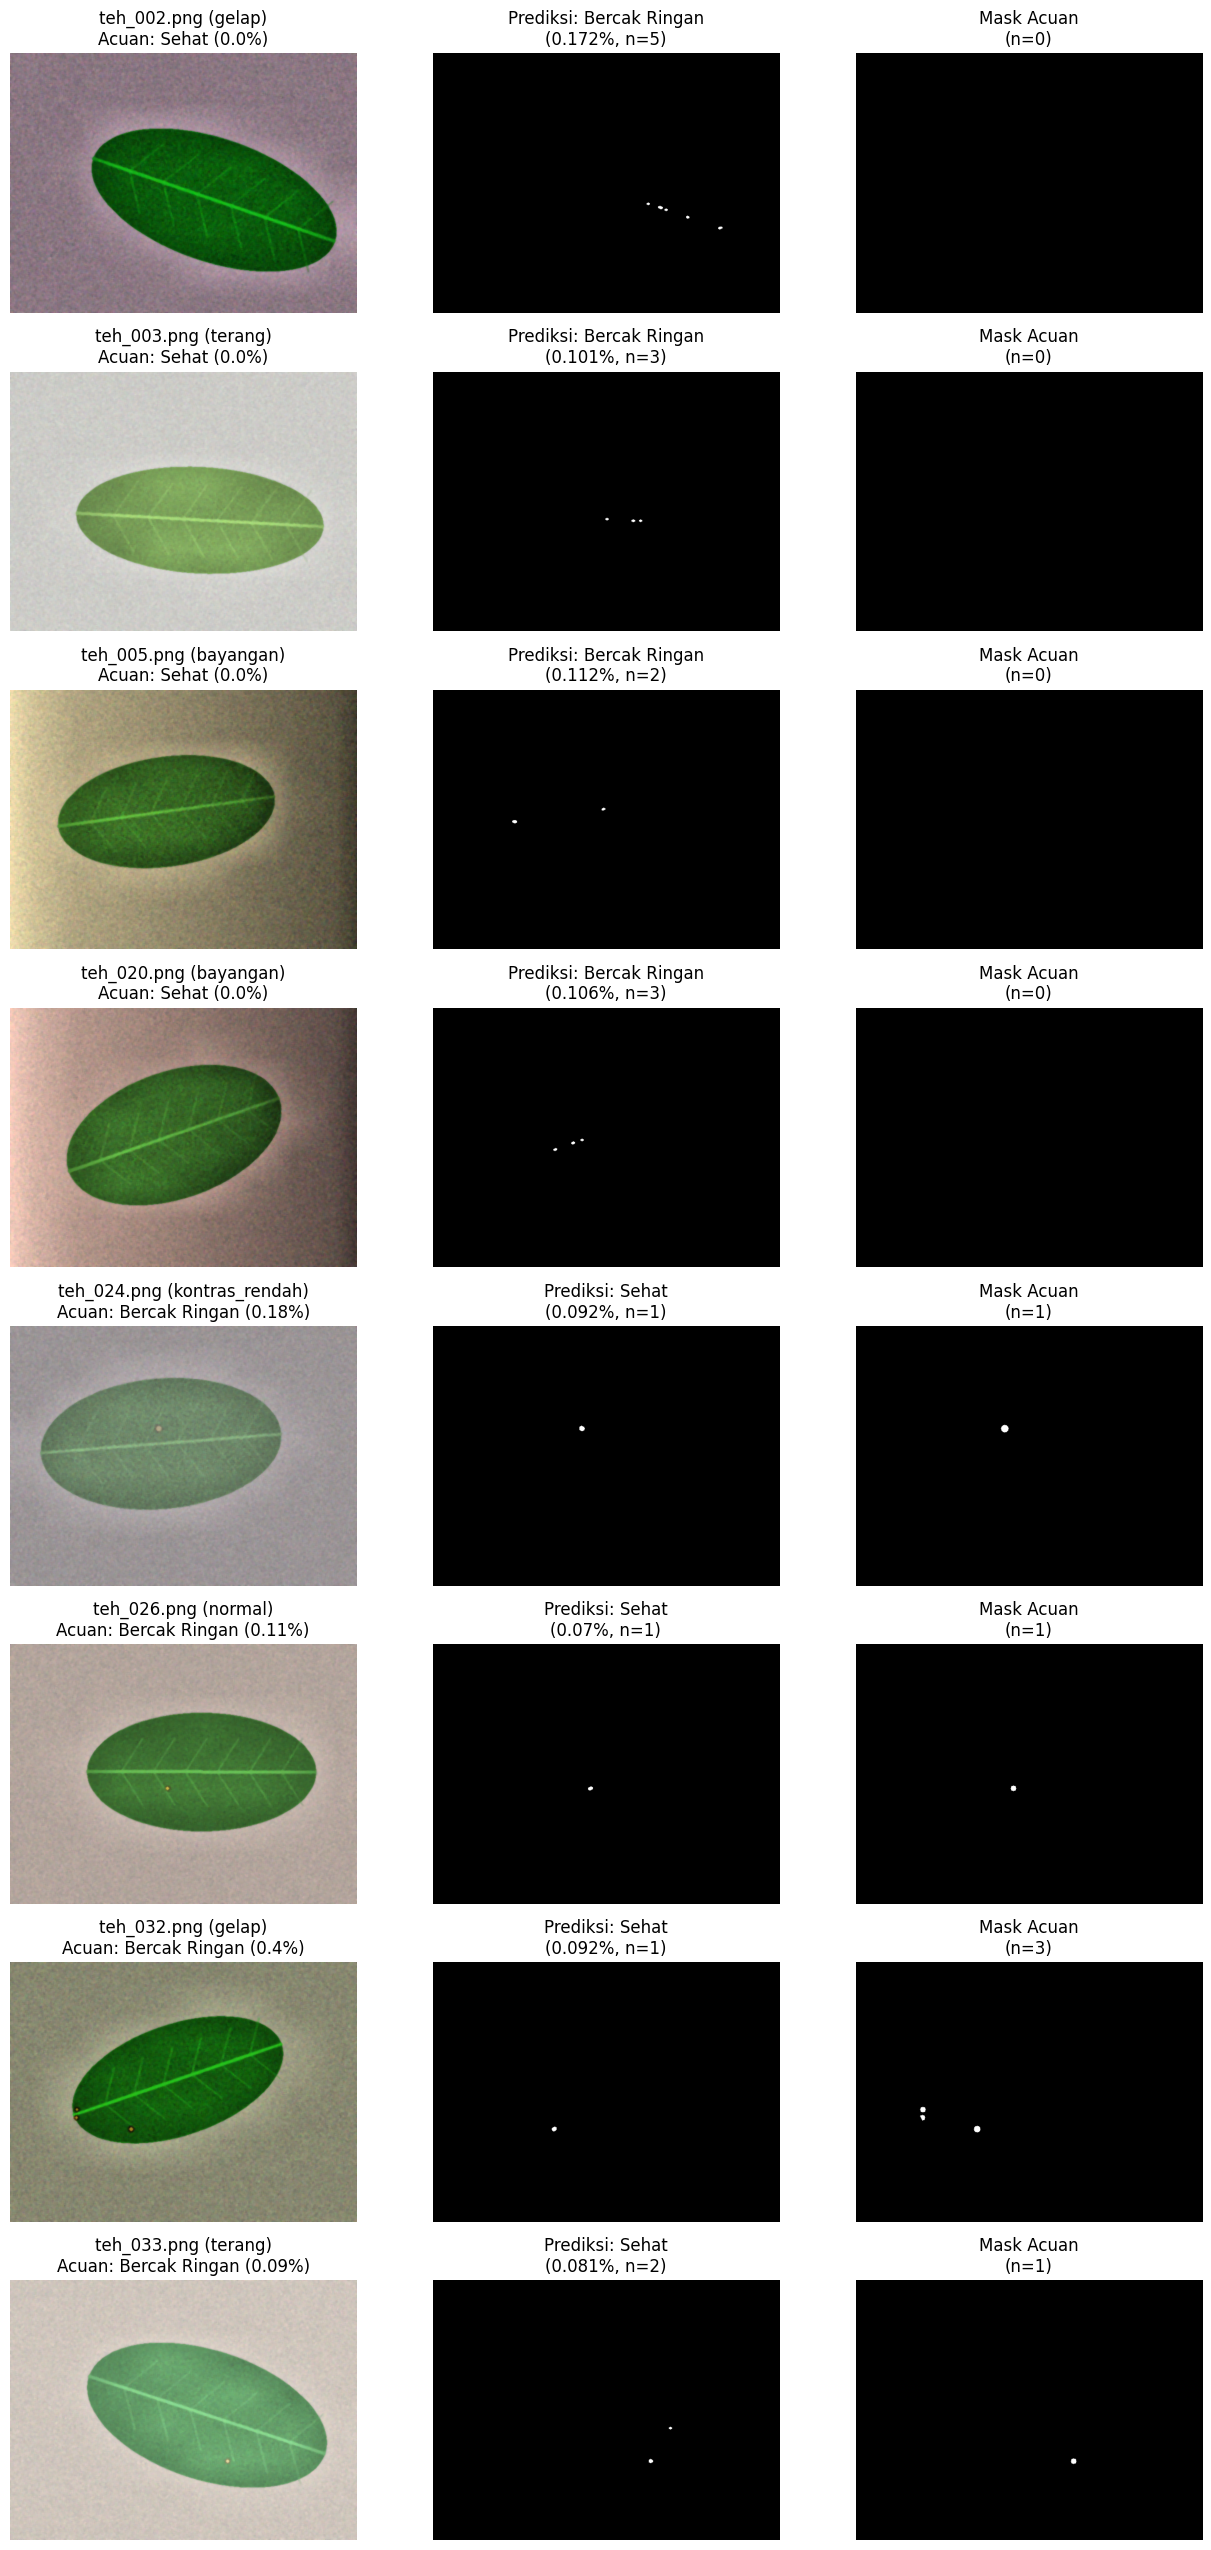

In [ ]:
# Langkah 5.3: Tampilkan setiap citra yang salah kelas beserta penyebabnya
salah = ev[ev.kelas_prediksi != ev.kelas_acuan].copy()
print(f"=== DAFTAR CITRA YANG SALAH KELAS (Total: {len(salah)} dari 60 citra) ===")
print(salah[["nama", "kondisi", "kelas_acuan", "kelas_prediksi",
             "persen_acuan", "persen_prediksi", "jumlah_acuan", "jumlah_prediksi"]])

if len(salah) > 0:
    panel_salah, judul_salah = [], []
    for _, r in salah.iterrows():
        img, md, mb = muat(r.nama)
        pra_ = praproses(img, PARAM)
        h = bercak.analisis_daun(pra_, PB)
        panel_salah += [pra_, h["mask_bercak"], mb]
        judul_salah += [
            f"{r.nama} ({r.kondisi})\nAcuan: {r.kelas_acuan} ({r.persen_acuan}%)",
            f"Prediksi: {r.kelas_prediksi}\n({r.persen_prediksi}%, n={r.jumlah_prediksi})",
            f"Mask Acuan\n(n={r.jumlah_acuan})"
        ]
    tampil(panel_salah, judul_salah, baris=len(salah), ukuran=(13, 3.2 * len(salah)))
    plt.savefig("../hasil/p6_salah_kelas.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
import os, shutil, zipfile

BASE_DIR = "/content/drive/MyDrive/simuteh-2330511031"
os.chdir(BASE_DIR)

# 0. Pastikan P5_tepi.ipynb dan P6_morfologi.ipynb terbaru tersalin ke folder notebook/
for nb in ["P5_tepi.ipynb", "P6_morfologi.ipynb"]:
    src_nb = f"/content/drive/MyDrive/Colab Notebooks/{nb}"
    dst_nb = os.path.join(BASE_DIR, "notebook", nb)
    if os.path.exists(src_nb):
        shutil.copy2(src_nb, dst_nb)
        print(f"Update terbaru {nb} disalin ke folder notebook/")

# 1. Tarik dulu dari GitHub supaya sinkron
!git pull origin main

# 2. Atur ulang identitas Git kamu (sama persis seperti kemarin)
!git config --global user.email "nazwa.syafia2016@gmail.com"
!git config --global user.name "nazwasm"

# 3. Tulis README.md gabungan (P1-P4 kemarin + P5-P6 sekarang)
baris_readme = [
    "# Praktikum SIMUTEH Computer Vision (P1 - P6)",
    "**NAMA:** Nazwa Syafiya Mirzal | **NIM / SEED:** 2330511031 / 1031 | **KELAS:** 7A",
    "",
    "## Cara Menjalankan",
    "1. Clone repositori ini ke Google Drive atau eksekusi langsung via Google Colab.",
    "2. Hubungkan (mount) Google Drive di sel pertama setiap notebook.",
    "3. Jalankan notebook secara berurutan:",
    "   - Evaluasi P1-P4: `notebook/B1_lingkungan.ipynb` hingga `notebook/B5_praproses.ipynb`",
    "   - Pertemuan 5 (Deteksi Tepi): `notebook/P5_tepi.ipynb`",
    "   - Pertemuan 6 (Morfologi & Komponen Terhubung): `notebook/P6_morfologi.ipynb`",
    "4. Gunakan opsi **Runtime > Restart and run all** untuk memastikan hasil dapat direproduksi tanpa error.",
    "",
    "---",
    "",
    "## Ringkasan Hasil (v0.1-praproses)",
    "- **Kanal Warna:** Kanal R (Merah) terbukti paling optimal memisahkan bercak dari daun sehat (KB tertinggi di berbagai kondisi).",
    "- **Perbaikan Cahaya:** Metode CLAHE pada kanal V (dari ruang warna HSV) dengan `clipLimit=2.0` dan `tileGridSize=8x8` berhasil mengangkat detail pada kondisi gelap dan bayangan tanpa menimbulkan *false color*.",
    "- **Penapisan Spasial:** Penapis Median dengan ukuran kernel 5x5 dipilih karena paling tangguh meredam derau *salt-and-pepper* (garam-merica) bawaan sensor sekaligus menjaga batas bercak kecil agar tidak ikut pudar.",
    "- **Parameter Praproses Final:**",
    "  - Lebar citra: 640px",
    "  - Koreksi Gamma: 1.0 (dinamis)",
    "  - CLAHE: clip 2.0, tile 8",
    "  - Penapis derau: Median, kernel 5",
    "  - Penajaman (Unsharp Mask): Dimatikan (0.0)",
    "",
    "---",
    "",
    "## Ringkasan Hasil Pertemuan 5 — Deteksi Tepi (v0.2-tepi)",
    "- **Perbandingan Operator & Kanal (40 Citra Berbercak):**",
    "  Kanal **R** sesudah praproses menghasilkan rerata skor **F1** tertinggi dibandingkan kanal Gray pada seluruh operator:",
    "  - **Canny (`30/90, sigma=2.0`):** `F1 = 0.981` (`P = 0.975`, `R = 0.986`)",
    "  - **LoG (`sigma=3.0, frac=0.2`):** `F1 = 0.949` (`P = 0.912`, `R = 0.997`)",
    "  - **Prewitt (`T = 75`):** `F1 = 0.928` (`P = 0.873`, `R = 0.996`)",
    "  - **Sobel (`T = 100`):** `F1 = 0.924` (`P = 0.867`, `R = 0.996`)",
    "- **Parameter Canny & Perbaikan Ambang Otomatis (`canny_persentil`):**",
    "  - Kombinasi `sigma = 1.0, ambang = 100/200` meraih F1 total tertinggi (`0.988`), sedangkan `sigma = 2.0, ambang = 30/90` (`F1 = 0.981`) dan `sigma = 1.0, ambang = 50/150` (`F1 = 0.984`) menjaga *recall* tepi bercak ringan tetap tinggi (`0.900 - 0.914`).",
    "  - Ambang otomatis berbasis persentil magnitudo gradien (`canny_persentil`) bekerja optimal pada **`q = 98`** (`F1 = 0.971` di kanal R), sesuai proporsi piksel tepi (~2% luas citra).",
    "- **Tepi Palsu pada Daun Sehat & Keputusan Pemakaian Tepi:**",
    "  - Kanal R menghasilkan **`0.0 piksel`** tepi palsu di bagian dalam daun sehat pada seluruh kondisi cahaya, sedangkan kanal Gray menghasilkan **`654.8 - 877.2 piksel`** tepi palsu akibat tulang daun.",
    "  - Deteksi tepi tidak digunakan untuk mengisi wilayah bercak (segmentasi luas), melainkan digantikan oleh pengambangan intensitas kanal R dan operasi morfologi pada Pertemuan 6.",
    "",
    "---",
    "",
    "## Ringkasan Hasil Pertemuan 6 — Morfologi & Modul Bercak (v0.3-morfologi)",
    "- **Operasi Morfologi & Penyaringan Komponen:**",
    "  - Menggunakan ambang awal `bercak_awal` pada **kanal R (`kanal = 2, k = 4.0`)**, diikuti operasi **Opening (`se_open = 5`)** lalu **Closing (`se_close = 5`)** dengan *Structuring Element* berbentuk **elips (`se_bentuk = \"elips\"`)**.",
    "  - Penyaringan komponen terhubung (konektivitas 8) berdasarkan ukuran dan bentuk (**`luas_min = 20` px**, **`bulat_min = 0.5`**, dan **`rasio_maks = 1.8`**) menurunkan galat jumlah bercak ke titik terendah (`1.25` pada kelas berat, `0.90` pada kelas ringan, dan `1.20` pada kelas sehat).",
    "- **Evaluasi Modul `src/bercak.py` pada 60 Citra:**",
    "  - **Galat absolut rerata (MAE) persen bercak:** `0.575%`",
    "  - **Korelasi persen prediksi vs acuan:** `0.957`",
    "  - **Akurasi klasifikasi kelas mutu:** `0.867` (**86.7%** — 52/60 citra tepat; `Bercak Berat` 20/20 tepat, `Bercak Ringan` 16/20 tepat, `Sehat` 16/20 tepat).",
    "",
    "---",
    "",
    "## Cara Memakai `analisis_daun` (`src/bercak.py`)",
    "```python",
    "import sys, json",
    "sys.path.append('src')",
    "from utils_cv import baca",
    "from praproses import praproses",
    "from bercak import analisis_daun",
    "",
    "param_pra = json.load(open('hasil/param_praproses.json'))",
    "param_bercak = json.load(open('hasil/param_bercak.json'))",
    "",
    "img = baca('data/sintetis/citra/teh_041.png')",
    "img_pra = praproses(img, param_pra)",
    "hasil = analisis_daun(img_pra, param_bercak)",
    "",
    "print('Jumlah bercak :', hasil['jumlah_bercak'])",
    "print('Persen bercak :', hasil['persen_bercak'], '%')",
    "print('Kelas mutu    :', hasil['kelas'])",
    "```"
]

with open("README.md", "w") as f:
    f.write("\n".join(baris_readme) + "\n")

if not os.path.exists("requirements.txt"):
    with open("requirements.txt", "w") as f:
        f.write("opencv-python>=4.8.0\nnumpy>=1.24.0\npandas>=2.0.0\nmatplotlib>=3.7.0\n")

# 4. Buat ZIP Kode_P5-P6_2330511031.zip untuk dikumpulkan ke LMS
nama_zip = "Kode_P5-P6_2330511031.zip"
file_wajib = [
    "README.md", "requirements.txt",
    "notebook/P5_tepi.ipynb", "notebook/P6_morfologi.ipynb",
    "src/utils_cv.py", "src/praproses.py", "src/utils_tepi.py", "src/bercak.py",
    "hasil/param_praproses.json", "hasil/param_bercak.json",
]
with zipfile.ZipFile(nama_zip, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in file_wajib:
        if os.path.exists(p):
            zf.write(p)
print("README.md dan Kode_P5-P6_2330511031.zip sudah siap!\n")

# 5. Commit Tahap 1: Pertemuan 5 + Beri Tag v0.2-tepi
!git add src/utils_tepi.py notebook/P5_tepi.ipynb hasil/p5_*
!git commit -m "Finalisasi Pertemuan 5: deteksi tepi dan keputusan pemakaian tepi"
!git tag -f v0.2-tepi

# 6. Commit Tahap 2: Pertemuan 6 + Beri Tag v0.3-morfologi
!git add src/bercak.py notebook/P6_morfologi.ipynb hasil/param_bercak.json hasil/p6_* README.md requirements.txt
!git commit -m "Finalisasi Pertemuan 6: operasi morfologi, integrasi bercak.py, dan update README"
!git tag -f v0.3-morfologi

# 7. Kirim seluruh commit dan kedua tag ke GitHub
!git push origin main
!git push --tags --force

remote: Enumerating objects: 5, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 3.06 KiB | 7.00 KiB/s, done.
From https://github.com/nazwasm/simuteh-2330511031
 * branch            main       -> FETCH_HEAD
   18208f6..c370195  main       -> origin/main
Updating 18208f6..c370195
Fast-forward
 README.md | 87 ++++++++++++++++++++++++++++++++++++++++++++++++++-------------
 1 file changed, 70 insertions(+), 17 deletions(-)
README.md dan Kode_P5-P6_2330511031.zip sudah siap!

